# Compare the saved decision-model features

Run this **after the compatibility pilot**, and again after full feature creation. This notebook reads permanent feature artifacts; it never contacts a provider, loads weights, trains a predictor or reads target values.

It asks: do the models choose the same class/direction? Are their probabilities similar? Which model differs most from the others? Does exact text reuse change those conclusions? How do the answers vary across datasets and text columns?

**No real features yet means no comparison results yet.** Coverage remains visible; all other figures appear automatically when suitable saved artifacts exist. Synthetic test fixtures are never displayed as research results.

[1/18] BIN_TEXT_FAKE_JOB_POSTING: 0 saved feature artifacts


[2/18] BIN_TEXT_JIGSAW_TOXICITY: 0 saved feature artifacts


[3/18] BIN_TEXT_KICKSTARTER_FUNDING: 0 saved feature artifacts


[4/18] MUL_TEXT_DATA_SCIENTIST_SALARY: 0 saved feature artifacts


[5/18] MUL_TEXT_MICHELIN_RESTAURANTS: 0 saved feature artifacts


...

[15/18] REG_TEXT_ROTTEN_TOMATOES: 0 saved feature artifacts


[16/18] REG_TEXT_SCIMAGOJR_IMPACT: 0 saved feature artifacts


[17/18] REG_TEXT_VANCOUVER_SALARIES: 0 saved feature artifacts


[18/18] REG_TEXT_VIDEO_GAMES_SALES: 0 saved feature artifacts


dataset,provider,representation,status
Fake Job Postings,jev,per_column,not_created
Fake Job Postings,liquid,per_column,not_created
Fake Job Postings,perplexity,per_column,not_created
Fake Job Postings,cloudflare,per_column,not_created
Fake Job Postings,strands,per_column,not_created
Fake Job Postings,intern,per_column,not_created
Fake Job Postings,jev,joint,not_created
Fake Job Postings,liquid,joint,not_created
Fake Job Postings,perplexity,joint,not_created
Fake Job Postings,cloudflare,joint,not_created


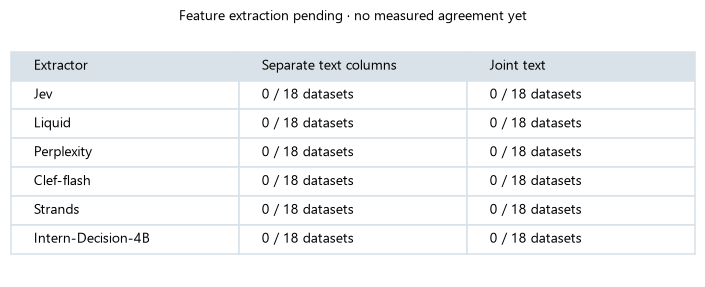

0/216 dataset/model/representation artifacts available.
No extraction is performed here. If several versions exist, pin artifact IDs in comparison.artifacts in the config.


In [1]:
import sys
from pathlib import Path
REPO_ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "pyproject.toml").is_file() and (p / "src").is_dir())
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))
import matplotlib.pyplot as plt
from src.utils.config import load_config, save_resolved_config
from src.utils.notebook_display import display_local
from src.utils.notebook_report import begin_report, report_section, record, finish_report
from src.evaluation.decision_comparison import compare_saved_features, dataset_balanced, save_comparison
from src.visualize import figures, style
from src.visualize.decision_comparison import coverage_figures, pair_figures, consensus_figures, distribution_figures, example_figures
style.apply()
NOTEBOOK = "2. feature_creation/04_decision_feature_comparison"
begin_report()
save = figures.FigureSaver(NOTEBOOK)
cfg = load_config("feature_comparison")
save_resolved_config(cfg, NOTEBOOK)
report_section("1. Saved features and provenance")
result = compare_saved_features(cfg)
inventory = result.table("inventory")
display_local(inventory[["dataset", "provider", "representation", "status"]])
record(inventory, "Exact selected model versions, question banks and artifact identities")
for fig, name, caption in coverage_figures(result, cfg["comparison"]):
    save(fig, name, caption=caption)
    display_local(fig)
    plt.close(fig)
print(f"{int(inventory.status.eq('available').sum())}/{len(inventory)} dataset/model/representation artifacts available.")
print("No extraction is performed here. If several versions exist, pin artifact IDs in comparison.artifacts in the config.")

## 2. Agreement and probability differences

Every comparison joins **the same source row and text column(s)**, then verifies identical text/question hashes and class order. Different text truncation, question versions or dataset versions stop the comparison.

- **Binary agreement:** both positive-class probabilities are at least 0.5, or both are below 0.5. This diagnostic threshold is unrelated to the later CV threshold optimization.
- **Multiclass agreement:** the largest probability belongs to the same class. Exact ties use the stored class order; the report counts ties.
- **Regression agreement:** expected scores have the same sign (lower / exactly zero / higher). The tables also count score differences within **0.5 scale points**, a configurable diagnostic tolerance, not target units.
- **Total variation:** half the sum of absolute probability differences. **Jensen–Shannon divergence:** a symmetric comparison of complete distributions. Both range from 0 (identical) to 1.

Every metric is calculated twice: once counting all source rows, and once counting identical inputs only once **within each text group**. Overall figures give each text group equal weight within a dataset, then each dataset equal weight. Tasks and separate/joint inputs remain separate. Pairwise sample counts are always retained.

In [2]:
report_section("2. Pairwise agreement and probability differences")
pairs = result.table("pairs")
display_local(pairs)
display_local(result.table("coverage"))
if pairs.empty:
    print("Pending: at least two models need complete saved features for the same dataset and representation.")
else:
    summary = dataset_balanced(pairs, ["task", "representation", "weighting", "model_a", "model_b"], ["agreement", "total_variation", "js_divergence", "scalar_mae"])
    display_local(summary)
for fig, name, caption in pair_figures(result, cfg["comparison"]):
    save(fig, name, caption=caption)
    display_local(fig)
    plt.close(fig)

Pending: at least two models need complete saved features for the same dataset and representation.


## 3. Which model is furthest from the others? How many agree?

For each model, calculate the average of the **other models**, excluding that model itself. Measure total variation from this average for classification, and absolute expected-score difference for regression. Also report how often each model is furthest; tied models share that count equally.

These rankings require the complete configured roster on the same inputs. During a partial pilot, pairwise comparisons remain available but no six-model consensus is fabricated. A unanimous vote means every model selects the same class/direction; other bars show the size of the largest agreeing group.

**Difference is not error, agreement is not correctness, and the average is not ground truth.** Downstream prediction on held-out folds is evaluated later. These diagnostics do not use target labels.

In [3]:
report_section("3. Distance from the other models and voting")
display_local(result.table("consensus"))
display_local(result.table("votes"))
if result.table("consensus").empty:
    print("Pending: consensus and outlier rankings require all configured providers on at least one shared dataset/representation.")
for fig, name, caption in consensus_figures(result, cfg["comparison"]):
    save(fig, name, caption=caption)
    display_local(fig)
    plt.close(fig)

Pending: consensus and outlier rankings require all configured providers on at least one shared dataset/representation.


## 4. Feature distributions and uncertainty

Per-dataset, per-text-column boxplots show positive-class probabilities, multiclass maximum probabilities, or regression expected scores. Additional plots show **normalized entropy**, computed identically from every model's retained probabilities: zero means all mass on one answer, one means uniform mass.

Entropy and maximum probability describe a model's reported confidence; they do not demonstrate calibration. For regression, the entire nine-option distribution is also compared: an expected score near zero can represent either neutral evidence or balanced mass at opposite extremes.

Whiskers show p01–p99, while the tables retain minima, maxima, means, standard deviations, missing counts and constant-feature flags. Long lists of text columns are split into readable pages.

In [4]:
report_section("4. Complete feature distributions")
display_local(result.table("distributions"))
if result.table("distributions").empty:
    print("Pending: no numeric feature distributions have been generated yet.")
for fig, name, caption in distribution_figures(result, cfg["comparison"]):
    save(fig, name, caption=caption)
    display_local(fig)
    plt.close(fig)

Pending: no numeric feature distributions have been generated yet.


## 5. Inspect the largest disagreements

The heatmaps display full probability vectors for a highly disagreeing input in each task type. The accompanying table keeps several examples per dataset/text group, with the stable `csv:N` row ID and the exact input hash. No target labels are consulted when selecting examples.

Paired scatterplots show whether one model is systematically more extreme than another. Only scatter points are sampled; every metric and quantile above uses all eligible inputs. For multiclass, scatter axes show maximum probability, so consult the vector heatmaps and agreement table to see which classes the models selected.

In [5]:
report_section("5. Disagreement examples and paired outputs")
display_local(result.table("examples"))
record(result.table("scatter"), "Deterministic scatter samples; not the metric calculation sample")
if result.table("examples").empty:
    print("Pending: no complete-roster disagreement examples are available.")
for fig, name, caption in example_figures(result, cfg["comparison"]):
    save(fig, name, caption=caption)
    display_local(fig)
    plt.close(fig)

Pending: no complete-roster disagreement examples are available.


## 6. Save the analysis and print the complete report

CSV tables and their source-artifact manifest are saved under `output_JEVPFN/results/notebooks/2. feature_creation/04_decision_feature_comparison/tables/`. These are local analysis outputs. The permanent paid features stay in `data/jev_cache/<dataset_id>.sqlite3` and are never rewritten by this notebook.

Captions join `output_JEVPFN/figures/Captions.md`; the full section-by-section report joins `output_JEVPFN/All Results.md`. Rerun this notebook as new complete provider artifacts arrive.

In [6]:
report_section("6. Saved analysis and interpretation")
analysis_folder = save_comparison(result, cfg, NOTEBOOK)
record(cfg["comparison"], "Exact comparison configuration")
record({"analysis_tables": str(analysis_folder), "target_labels_used": False, "provider_calls": 0, "cache_writes": 0}, "Storage and execution contract")
finish_report(NOTEBOOK, f"""Saved artifacts: {int(inventory.status.eq('available').sum())}/{len(inventory)}.
Pairwise metric rows: {len(result.table('pairs'))}; consensus metric rows: {len(result.table('consensus'))}.
All metric calculations use all eligible rows, with a separate exact-input weighting.
No feature creation, API calls, target-label analysis or model training took place.
A model furthest from the others is the most different, not necessarily the least useful.
Analysis tables: {analysis_folder}
""" + save.summary())

2. feature_creation/04_decision_feature_comparison

1. Saved features and provenance

              dataset   provider representation      status
    Fake Job Postings        jev     per_column not_created
    Fake Job Postings     liquid     per_column not_created
    Fake Job Postings perplexity     per_column not_created
    Fake Job Postings cloudflare     per_column not_created
    Fake Job Postings    strands     per_column not_created
    Fake Job Postings     intern     per_column not_created
    Fake Job Postings        jev          joint not_created
    Fake Job Postings     liquid          joint not_created
    Fake Job Postings perplexity          joint not_created
    Fake Job Postings cloudflare          joint not_created
    Fake Job Postings    strands          joint not_created
    Fake Job Postings     intern          joint not_created
      Jigsaw Toxicity        jev     per_column not_created
      Jigsaw Toxicity     liquid     per_column not_created
      Jigsaw T